# Inventario documental

Exploración del inventario en `data/processed/corpus/inventario_documental.csv`.


In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

import pandas as pd
import matplotlib.pyplot as plt

INV = ROOT / "data" / "processed" / "corpus" / "inventario_documental.csv"
df = pd.read_csv(INV)
for col in ("n_pages", "chars", "words", "bytes"):
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df.head()


,doc_id,tipo_documento,titulo,dominio,prioridad,url_origen,fecha_consulta,formato,local_path,bytes,sha256,n_pages,chars,words,texto_extraible,estado_descarga,estado_extraccion,notas
0,D001,reglamento_academico,Reglamento académico,academico,alta,https://uma.edu.pe/documentos/reglamentos%20y%...,2026-10-09,pdf,data/raw/public_documents/D001__Reglamento-aca...,329074,6ba652e42cf6ab7e6f5a16c46d377bd93e9628a630fbfa...,16,44872,6567,True,cached,ok,NaN
1,D002,reglamento_matricula,Reglamento general de matrícula,matricula,alta,https://uma.edu.pe/documentos/reglamentos%20y%...,2026-10-09,pdf,data/raw/public_documents/D002__REGLAMENTO_DE_...,144749,67278a04d3ec4addcf01cb4ffb9e29fc6685a4112f26af...,5,13998,2082,True,cached,ok,NaN
2,D003,reglamento_general,Reglamento general de la UMA (2025),institucional,alta,https://uma.edu.pe/documentos/reglamentos%20y%...,2026-10-09,pdf,data/raw/public_documents/D003__REGLAMENTO_GEN...,338781,c8356c9778d67e0374d107ba00bf8a5f9ccba67b0627d2...,18,55362,7954,True,cached,ok,NaN
3,D004,reglamento_economico,Reglamento económico universitario,economico,alta,https://uma.edu.pe/documentos/reglamentos%20y%...,2026-10-09,pdf,data/raw/public_documents/D004__Reglamento_eco...,174351,2834de6ac6207f03dcc1605247e269bd88317223c58767...,5,10478,1625,True,cached,ok,NaN
4,D005,grados_titulos,Reglamento de grados y títulos,tramites,alta,https://uma.edu.pe/documentos/reglamentos%20y%...,2026-10-09,pdf,data/raw/public_documents/D005__043-Reglamento...,285552,9680557c89861f53c0a5f1179b1c07a60f0ca95abaa9d8...,20,57927,8623,True,cached,ok,NaN


## Tabla resumida

In [2]:
cols = [
    "doc_id", "tipo_documento", "titulo", "dominio", "formato",
    "n_pages", "bytes", "words", "texto_extraible", "estado_extraccion",
]
display(df[cols])


,doc_id,tipo_documento,titulo,dominio,formato,n_pages,bytes,words,texto_extraible,estado_extraccion
0,D001,reglamento_academico,Reglamento académico,academico,pdf,16,329074,6567,True,ok
1,D002,reglamento_matricula,Reglamento general de matrícula,matricula,pdf,5,144749,2082,True,ok
2,D003,reglamento_general,Reglamento general de la UMA (2025),institucional,pdf,18,338781,7954,True,ok
3,D004,reglamento_economico,Reglamento económico universitario,economico,pdf,5,174351,1625,True,ok
4,D005,grados_titulos,Reglamento de grados y títulos,tramites,pdf,20,285552,8623,True,ok
5,D006,admision_pregrado,Reglamento de admisión de pregrado,admision,pdf,8,199206,3193,True,ok
6,D007,becas,Reglamento de becas,economico,pdf,10,220332,3161,True,ok
7,D008,tutoria,Reglamento del sistema de tutoría universitaria,academico,pdf,7,299990,2795,True,ok
8,D009,convalidaciones,Reglamento de convalidaciones y/o reconocimien...,academico,pdf,3,217783,1074,True,ok
9,D010,proceso_matricula,Proceso de matrícula (guía),matricula,pdf,1,648954,128,True,weak_or_scanned


## Conteos por dominio, tipo y formato

In [3]:
print("Por dominio:")
display(df["dominio"].value_counts().sort_index())
print("Por tipo_documento:")
display(df["tipo_documento"].value_counts().sort_index())
print("Por formato:")
display(df["formato"].value_counts().sort_index())


Por dominio:


dominio
academico        3
admision         1
economico        3
institucional    1
matricula        2
orientacion      1
tramites         1
Name: count, dtype: int64

Por tipo_documento:


tipo_documento
admision_pregrado       1
becas                   1
convalidaciones         1
faq_web                 1
grados_titulos          1
proceso_matricula       1
reglamento_academico    1
reglamento_economico    1
reglamento_general      1
reglamento_matricula    1
tarifario               1
tutoria                 1
Name: count, dtype: int64

Por formato:


formato
html     1
pdf     11
Name: count, dtype: int64

## Páginas, bytes y duplicados SHA256

In [4]:
print(f"Documentos: {len(df)}")
print(f"Páginas (suma n_pages): {int(df['n_pages'].fillna(0).sum())}")
print(f"Bytes (suma): {int(df['bytes'].fillna(0).sum()):,}".replace(",", " "))
dup = df[df.duplicated(subset=["sha256"], keep=False)].sort_values("sha256")
if dup.empty:
    print("SHA256: sin duplicados en el inventario.")
else:
    display(dup[["doc_id", "sha256", "bytes", "n_pages"]])


Documentos: 12
Páginas (suma n_pages): 102
Bytes (suma): 4 216 322
SHA256: sin duplicados en el inventario.


## Extracción débil (`estado_extraccion != ok`)

In [5]:
weak = df[df["estado_extraccion"] != "ok"]
if weak.empty:
    print("Todos los registros tienen estado_extraccion=ok.")
else:
    display(weak[["doc_id", "titulo", "estado_extraccion", "words", "notas"]])


,doc_id,titulo,estado_extraccion,words,notas
9,D010,Proceso de matrícula (guía),weak_or_scanned,128,NaN


## Gráficos

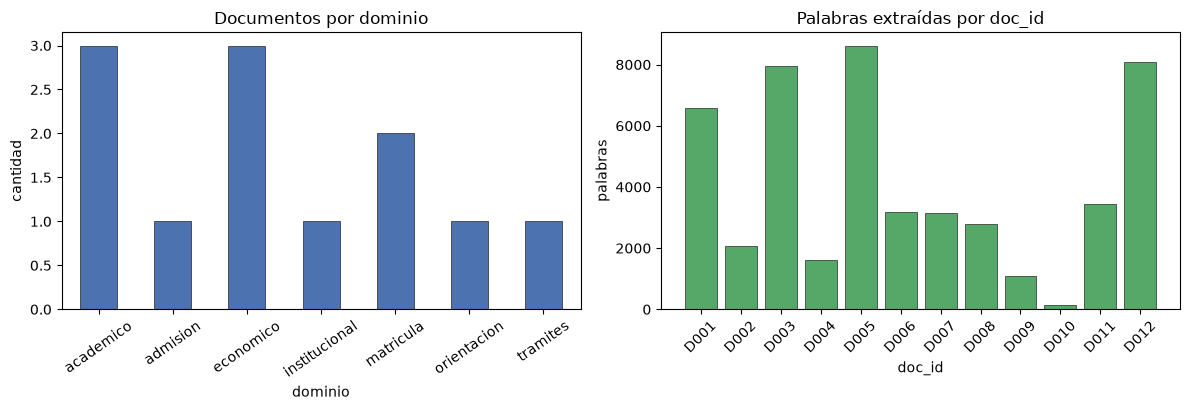

Guardado (dominio): /Users/cesarsanchez/Documents/04-archivo/01-educacion/01-universidad/1_FIIS_UNI/3_Term-III/Investigacion 1/Investigacion-Tesis/3_Sustentacion/3_entregable_curso_tesis/semana4/reports/figures/eda_docs_por_dominio.png


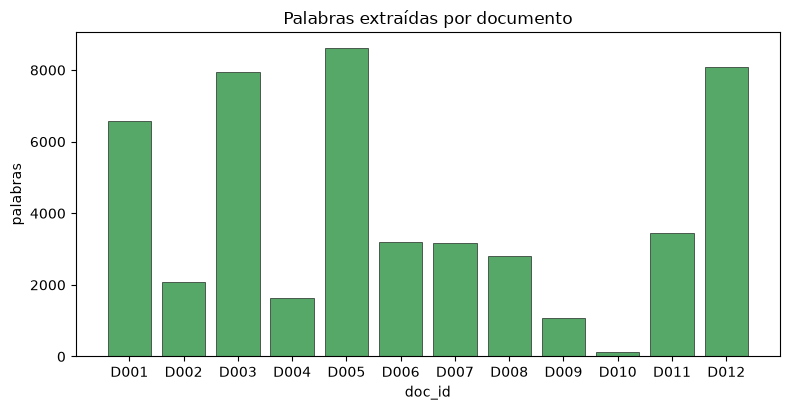

Guardado: /Users/cesarsanchez/Documents/04-archivo/01-educacion/01-universidad/1_FIIS_UNI/3_Term-III/Investigacion 1/Investigacion-Tesis/3_Sustentacion/3_entregable_curso_tesis/semana4/reports/figures/eda_palabras_por_doc.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

by_dom = df["dominio"].value_counts().sort_index()
by_dom.plot(kind="bar", ax=axes[0], color="#4C72B0", edgecolor="black", linewidth=0.4)
axes[0].set_title("Documentos por dominio")
axes[0].set_xlabel("dominio")
axes[0].set_ylabel("cantidad")
axes[0].tick_params(axis="x", rotation=35)

axes[1].bar(df["doc_id"], df["words"], color="#55A868", edgecolor="black", linewidth=0.4)
axes[1].set_title("Palabras extraídas por doc_id")
axes[1].set_xlabel("doc_id")
axes[1].set_ylabel("palabras")
axes[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
out = ROOT / "reports" / "figures" / "eda_docs_por_dominio.png"
out.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out, dpi=140, bbox_inches="tight")
plt.show()
print(f"Guardado (dominio): {out}")

fig2, ax2 = plt.subplots(figsize=(8, 4.2))
ax2.bar(df["doc_id"], df["words"], color="#55A868", edgecolor="black", linewidth=0.4)
ax2.set_title("Palabras extraídas por documento")
ax2.set_xlabel("doc_id")
ax2.set_ylabel("palabras")
fig2.tight_layout()
out2 = ROOT / "reports" / "figures" / "eda_palabras_por_doc.png"
fig2.savefig(out2, dpi=140)
plt.show()
print(f"Guardado: {out2}")


## Conclusiones

### Interpretaciones

- Hay **12 fuentes públicas** (~102 páginas), sin duplicados por hash. El piloto ya tiene materia prima normativa, no solo una FAQ suelta.
- El peso está en **académico y económico** (3 docs cada uno). Matrícula, trámites, admisión y orientación aparecen, pero con menos piezas.
- **11 PDF + 1 HTML (FAQ)**. La FAQ (D012) será ancla frecuente de preguntas; los reglamentos son la referencia cuando haya conflicto.
- **D010** (proceso de matrícula) es el único con extracción débil: casi no aporta texto útil al índice.

| Decisión | Por qué |
|----------|--------|
| Incluir en el índice RAG: D001–D009, D011, D012 | Extracción usable y cobertura de dominios clave |
| Aislar o excluir D010 del retrieval hasta OCR/versión texto | Evitar ruido y falsa cobertura de matrícula operativa |
| Priorizar gestiones de datos: malla facultad, calendario, consultas reales anonimizadas | Sin eso el experimento A3 (herramientas) y fechas de ciclo quedan incompletos |

